In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [55]:
df = pd.read_csv("d:\\project\\16. Recommendation System\\anime.csv")

In [56]:
df.head()

,anime_id,name,genre,type,episodes,rating,members
0,32281,Kimi no Na wa.,"Drama, Romance, School, Supernatural",Movie,1,9.37,200630
1,5114,Fullmetal Alchemist: Brotherhood,"Action, Adventure, Drama, Fantasy, Magic, Mili...",TV,64,9.26,793665
2,28977,Gintama°,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51,9.25,114262
3,9253,Steins;Gate,"Sci-Fi, Thriller",TV,24,9.17,673572
4,9969,Gintama&#039;,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51,9.16,151266


In [57]:
df.tail()

,anime_id,name,genre,type,episodes,rating,members
12289,9316,Toushindai My Lover: Minami tai Mecha-Minami,Hentai,OVA,1,4.15,211
12290,5543,Under World,Hentai,OVA,1,4.28,183
12291,5621,Violence Gekiga David no Hoshi,Hentai,OVA,4,4.88,219
12292,6133,Violence Gekiga Shin David no Hoshi: Inma Dens...,Hentai,OVA,1,4.98,175
12293,26081,Yasuji no Pornorama: Yacchimae!!,Hentai,Movie,1,5.46,142


In [58]:
df.shape

(12294, 7)

In [59]:
df.describe()

,anime_id,rating,members
count,12294.000000,12064.000000,1.229400e+04
mean,14058.221653,6.473902,1.807134e+04
std,11455.294701,1.026746,5.482068e+04
min,1.000000,1.670000,5.000000e+00
25%,3484.250000,5.880000,2.250000e+02
50%,10260.500000,6.570000,1.550000e+03
75%,24794.500000,7.180000,9.437000e+03
max,34527.000000,10.000000,1.013917e+06


In [60]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12294 entries, 0 to 12293
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   anime_id  12294 non-null  int64  
 1   name      12294 non-null  str    
 2   genre     12232 non-null  str    
 3   type      12269 non-null  str    
 4   episodes  12294 non-null  str    
 5   rating    12064 non-null  float64
 6   members   12294 non-null  int64  
dtypes: float64(1), int64(2), str(4)
memory usage: 1.3 MB


In [61]:


df['episodes'] = df['episodes'].replace('Unknown', np.nan)

In [62]:
df.isnull().sum()

anime_id      0
name          0
genre        62
type         25
episodes    340
rating      230
members       0
dtype: int64

In [63]:
df.isnull().sum().sum()

np.int64(657)

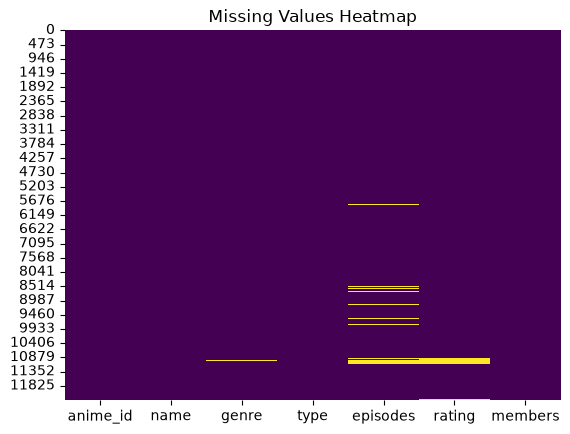

In [64]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Missing Values Heatmap')
plt.show()

In [65]:
df.dropna(axis=1)

,anime_id,name,members
0,32281,Kimi no Na wa.,200630
1,5114,Fullmetal Alchemist: Brotherhood,793665
2,28977,Gintama°,114262
3,9253,Steins;Gate,673572
4,9969,Gintama&#039;,151266
...,...,...,...
12289,9316,Toushindai My Lover: Minami tai Mecha-Minami,211
12290,5543,Under World,183
12291,5621,Violence Gekiga David no Hoshi,219
12292,6133,Violence Gekiga Shin David no Hoshi: Inma Dens...,175


In [66]:
df['genre'] = df['genre'].fillna('Unknown')

In [67]:
df['type'] = df['type'].fillna(df['type'].mode()[0])

In [68]:
df['rating'] = df['rating'].fillna(df['rating'].median())

In [69]:
df.isnull().sum()

anime_id      0
name          0
genre         0
type          0
episodes    340
rating        0
members       0
dtype: int64

In [70]:
features = df[['genre', 'type', 'episodes', 'rating', 'members']]

In [71]:
from sklearn.preprocessing import MultiLabelBinarizer

mlb = MultiLabelBinarizer()

genre_encoded = mlb.fit_transform(
    features['genre'].apply(lambda x: x.split(', '))
)

genre_df = pd.DataFrame(
    genre_encoded,
    columns=mlb.classes_,
    index=df.index
)

In [72]:
type_encoded = pd.get_dummies(features['type'], prefix='type', dtype=int)

In [73]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

numerical_features = features[['episodes', 'rating', 'members']]

scaled_features = scaler.fit_transform(numerical_features)

scaled_df = pd.DataFrame(
    scaled_features,
    columns=['episodes', 'rating', 'members'],
    index=df.index
)

In [74]:
final_features = pd.concat(
    [genre_df, type_encoded, scaled_df],
    axis=1
)

final_features.head()

,Action,Adventure,Cars,Comedy,Dementia,Demons,Drama,Ecchi,Fantasy,Game,...,Yuri,type_Movie,type_Music,type_ONA,type_OVA,type_Special,type_TV,episodes,rating,members
0,0,0,0,0,0,0,1,0,0,0,...,0,1,0,0,0,0,0,-0.242888,2.845534,3.330241
1,1,1,0,0,0,0,1,0,1,0,...,0,0,0,0,0,0,1,1.101445,2.737388,14.148406
2,1,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0.824043,2.727556,1.754713
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0.247900,2.648904,11.957666
4,1,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0.824043,2.639073,2.429742


In [76]:
final_features.isnull().sum()

Action             0
Adventure          0
Cars               0
Comedy             0
Dementia           0
Demons             0
Drama              0
Ecchi              0
Fantasy            0
Game               0
Harem              0
Hentai             0
Historical         0
Horror             0
Josei              0
Kids               0
Magic              0
Martial Arts       0
Mecha              0
Military           0
Music              0
Mystery            0
Parody             0
Police             0
Psychological      0
Romance            0
Samurai            0
School             0
Sci-Fi             0
Seinen             0
Shoujo             0
Shoujo Ai          0
Shounen            0
Shounen Ai         0
Slice of Life      0
Space              0
Sports             0
Super Power        0
Supernatural       0
Thriller           0
Unknown            0
Vampire            0
Yaoi               0
Yuri               0
type_Movie         0
type_Music         0
type_ONA           0
type_OVA     

In [77]:
final_features = final_features.fillna(final_features.median())

In [78]:
final_features = final_features.fillna(0)

In [79]:
final_features.isnull().sum().sum()

np.int64(0)

In [80]:
from sklearn.metrics.pairwise import cosine_similarity

cosine_sim = cosine_similarity(final_features)

In [85]:
def recommend_anime(anime_name, threshold=0.3):

    if anime_name not in df['name'].values:
        print("Anime not found!")
        return

    # Get index of selected anime
    idx = df[df['name'] == anime_name].index[0]

    # Get similarity scores
    similarity_scores = list(enumerate(cosine_sim[idx]))

    # Sort similarity scores in descending order
    similarity_scores = sorted(
        similarity_scores,
        key=lambda x: x[1],
        reverse=True
    )

    # Filter based on threshold and exclude selected anime
    recommendations = [
        (i, score) for i, score in similarity_scores
        if i != idx and score >= threshold
    ]

    # Display recommendations
    recommendations = recommendations[:10]

    if len(recommendations) == 0:
        print("No similar anime found for this threshold.")
        return

    result = pd.DataFrame({
        'Anime': [df.loc[i, 'name'] for i, score in recommendations],
        'Similarity Score': [score for i, score in recommendations]
    })

    return result

In [82]:
recommend_anime('Naruto', threshold=0.3)

,Anime,Similarity Score
0,Fairy Tail,0.980507
1,Bleach,0.964957
2,Hunter x Hunter (2011),0.962398
3,D.Gray-man,0.957780
4,Soul Eater,0.945435
5,Dragon Ball,0.941231
6,Fullmetal Alchemist: Brotherhood,0.941219
7,Fullmetal Alchemist,0.937363
8,Shingeki no Kyojin,0.937037
9,Kill la Kill,0.934792


In [83]:
thresholds = [0.2, 0.3, 0.5, 0.7, 0.9]

for threshold in thresholds:

    print("\nThreshold:", threshold)

    result = recommend_anime('Naruto', threshold)

    if result is not None:
        print(result)


Threshold: 0.2
                              Anime  Similarity Score
0                        Fairy Tail          0.980507
1                            Bleach          0.964957
2            Hunter x Hunter (2011)          0.962398
3                        D.Gray-man          0.957780
4                        Soul Eater          0.945435
5                       Dragon Ball          0.941231
6  Fullmetal Alchemist: Brotherhood          0.941219
7               Fullmetal Alchemist          0.937363
8                Shingeki no Kyojin          0.937037
9                      Kill la Kill          0.934792

Threshold: 0.3
                              Anime  Similarity Score
0                        Fairy Tail          0.980507
1                            Bleach          0.964957
2            Hunter x Hunter (2011)          0.962398
3                        D.Gray-man          0.957780
4                        Soul Eater          0.945435
5                       Dragon Ball          0.941

In [84]:
df.columns

Index(['anime_id', 'name', 'genre', 'type', 'episodes', 'rating', 'members'],
      dtype='str')

## User-Based Collaborative Filtering
- Finds users who have similar interests or preferences.
- Recommends items that similar users have liked or rated highly.
- Focuses on similarities between users. 

## Item-Based Collaborative Filtering
- Finds similarities between items based on user ratings or interactions.
- Recommends items similar to the ones a user already likes.
- Focuses on similarities between items rather than users.

**Collaborative Filtering is a recommendation technique that suggests products, movies, anime or other items based on the preferences, ratings and behaviour of multiple users.**

Types of Collaborative Filtering
1. User-Based Collaborative Filtering: Recommends items based on users with similar preferences.
2. Item-Based Collaborative Filtering: Recommends items based on similarities between items.